In [1]:
from tqdm import tqdm
from astropy.table import Table
import halotools
from halotools.mock_observables import return_xyz_formatted_array
from halotools.mock_observables import tpcf_jackknife
import matplotlib.pyplot as plt
import os
import h5py
import numpy as np
import pickle
import data
import sample
import stats
import plot
import pandas as pd

TNG_H = 0.6774

In [2]:
## Load data ###
hydro_full = pd.read_csv('data/cache_files/hydro_color_tree_subhaloflag_check_data.csv', usecols=['SubhaloMass', 'StellarMass', 'x', 'y', 'z',
                                                                           'logStellarMass', 'logSubhaloMass', 'g-i', "mpeak", "a12"])
print("\nHydro Table")
print(len(hydro_full))


# 1.4 * 10^8 minimum on Stellar Mass for hydro catalog
hydro_full = hydro_full[hydro_full['StellarMass'] >= (1.4 * 10**8 * TNG_H)]
print("\nNew Hydro Table Length:")
print(len(hydro_full))


Hydro Table
101364

New Hydro Table Length:
29365


In [3]:
def generate_randoms(Lbox, number):
    """Generate randoms to be used for tpcf_jackknife
    Args:
        Lbox: size of TNG simulation box
        number: desired number of randoms, i.e. 10,000
    Return:
        Nran: xyz formatted array of uniform random variables
    """
    Xran = np.random.uniform(0, Lbox, number)
    Yran = np.random.uniform(0, Lbox, number)
    Zran = np.random.uniform(0, Lbox, number)
    Nran = return_xyz_formatted_array(Xran, Yran, Zran)
    return Nran


In [6]:
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm

Lbox = 110.7 * TNG_H  # TNG box size in Mpc /h
rbins = np.logspace(np.log10(0.1), np.log10(24.9), 16)
rbin_centers = 0.5 * (rbins[1:] + rbins[:-1])

# ======================================================
# 1. Build mass-threshold samples
# ======================================================
t_thres = []
for ii in tqdm(range(7, 11)):
    ti = sample.mass_sample(
        hydro_full,
        'logStellarMass',
        ii,
        float('inf')
    )
    t_thres.append(ti)

# ======================================================
# 2. Extract XYZ positions
# ======================================================
pos_thres = [] # Units Mpc / h
for ii in tqdm(range(len(t_thres))):
    pos = return_xyz_formatted_array(
        t_thres[ii]['x'],
        t_thres[ii]['y'],
        t_thres[ii]['z']
    )
    pos_thres.append(pos)

# ======================================================
# 3. Generate random catalogs
# ======================================================
randoms = []
for kk in tqdm(range(10)):
    randk = generate_randoms(Lbox, 50000)
    randoms.append(randk)

print('Randoms computed')

# ======================================================
# 4. Compute TPCF + covariance (jackknife)
# ======================================================
xi_thres = []
cov_thres = []

pairs = [(0, 2), (1, 3), (2, 4), (3, 5)]

for ii, jj in tqdm(pairs):
    xi, cov = tpcf_jackknife(
        pos_thres[ii],
        randoms[jj],
        rbins,
        Nsub=3,
        period=Lbox,
        num_threads='max'
    )
    xi_thres.append(xi)
    cov_thres.append(cov)

# ======================================================
# 5. Organize outputs
# ======================================================
xi_threshold = {
    '10^7': xi_thres[0],
    '10^8': xi_thres[1],
    '10^9': xi_thres[2],
    '10^10': xi_thres[3],
}

cov_threshold = {
    '10^7': cov_thres[0],
    '10^8': cov_thres[1],
    '10^9': cov_thres[2],
    '10^10': cov_thres[3],
}

100%|██████████████████████████████████████████████████████████████████████████████████| 10/10 [00:00<00:00, 163.67it/s]


Randoms computed


100%|█████████████████████████████████████████████████████████████████████████████████████| 4/4 [03:15<00:00, 48.93s/it]


In [7]:
# Compute jackknife errors
errors = {
    key: stats.compute_tpcf_jackknife_errors(cov)
    for key, cov in cov_threshold.items()
}

# ======================================================
# 6. Plot: overlay all mass thresholds
# ======================================================
labels = {
    '10^7': r'$M_{\rm star} > 10^{7} \enspace h^{-1} M_\odot $',
    '10^8': r'$M_{\rm star} > 10^{8} \enspace h^{-1} M_\odot $',
    '10^9': r'$M_{\rm star} > 10^{9} \enspace h^{-1} M_\odot $',
    '10^10': r'$M_{\rm star} >10^{10} \enspace h^{-1} M_\odot$',
}

colors = {
    '10^7': 'C0',
    '10^8': 'C1',
    '10^9': 'C2',
    '10^10': 'C3',
}

In [8]:
import matplotlib.pyplot as plt
import matplotlib as mpl

# Set global font size for all text elements (optional, can be overridden)
mpl.rcParams['font.size'] = 20

# Set global font size for axis labels
mpl.rcParams['axes.labelsize'] = 30

# Set global font size for tick numbers
mpl.rcParams['xtick.labelsize'] = 20
mpl.rcParams['ytick.labelsize'] = 20

# Set tick widths and sizes globally
mpl.rcParams['xtick.major.width'] = 3
mpl.rcParams['ytick.major.width'] = 3
mpl.rcParams['xtick.minor.width'] = 3
mpl.rcParams['ytick.minor.width'] = 3

mpl.rcParams['xtick.minor.size'] = 3
mpl.rcParams['ytick.minor.size'] = 3
mpl.rcParams['xtick.major.size'] = 5
mpl.rcParams['ytick.major.size'] = 5

# Set axes line width globally
mpl.rcParams['axes.linewidth'] = 3 # Sets the width of the spines

In [ ]:
import matplotlib.pyplot as plt
import matplotlib as mpl

# Set global font size for all text elements (optional, can be overridden)
mpl.rcParams['font.size'] = 30

# Set global font size for axis labels
mpl.rcParams['axes.labelsize'] = 30

# Set global font size for tick numbers
mpl.rcParams['xtick.labelsize'] = 30
mpl.rcParams['ytick.labelsize'] = 30

# Set tick widths and sizes globally
mpl.rcParams['xtick.major.width'] = 3
mpl.rcParams['ytick.major.width'] = 3
mpl.rcParams['xtick.minor.width'] = 3
mpl.rcParams['ytick.minor.width'] = 3

mpl.rcParams['xtick.minor.size'] = 6
mpl.rcParams['ytick.minor.size'] = 6
mpl.rcParams['xtick.major.size'] = 7
mpl.rcParams['ytick.major.size'] = 7

# Set axes line width globally
mpl.rcParams['axes.linewidth'] = 3 # Sets the width of the spines

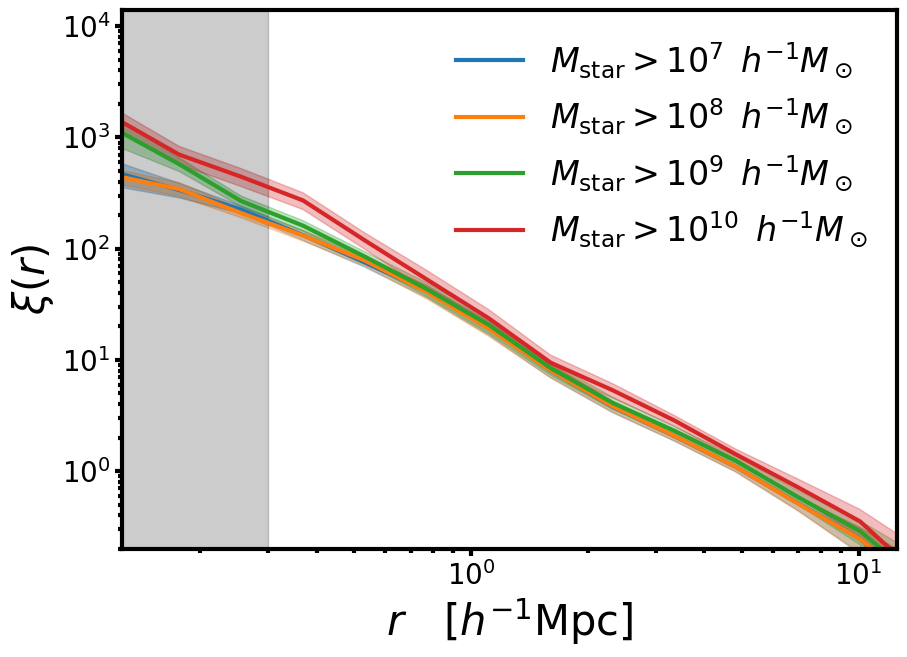

In [38]:
fig, ax = plt.subplots(figsize=(10, 7))

# Common errorbar style
err_kwargs = dict(
    fmt='o',
    markersize=7,
    color='black',
    elinewidth=2.5,
    capsize=5,
    capthick=2.5,
    markeredgewidth=1.5,
    alpha=1.0
)


for key in ['10^7', '10^8', '10^9', '10^10']:
    xi = xi_threshold[key]
    err = errors[key]

    # Protect log-scale plotting
    y_low = np.maximum(xi - err, 1e-6)

    ax.plot(
        rbin_centers,
        xi,
        color=colors[key],
        label=labels[key],
        markersize = 8,
        linewidth = 3
    )
    ax.fill_between(
        rbin_centers,
        y_low,
        xi + err,
        color=colors[key],
        alpha=0.3
    )

# ======================================================
# 7. Formatting
# ======================================================
ax.set_xscale('log')
ax.set_yscale('log')

ax.set_xlabel(r'$r \quad [h^{-1} \rm Mpc]$')
ax.set_ylabel(r'$\xi(r)$')

ax.set_ylim(10*10**-3, 10*10**2.3)

ax.set_xlim(10**(-0.9), 10**(1.1)) # Based on Hadzhiyska
ax.set_ylim(0.2, 14000) # Based on Hadzhiyska
## axes[0].set_ylabel(r'$\xi(r)$')

ax.fill_betweenx([-2, 14000], 0.1, 0.3, color="k", alpha=0.2)
ax.legend(loc='upper right', frameon = False)
#ax.grid(False)

#plt.tight_layout()
#plt.show()


In [39]:
fig.savefig('mass_thres.png', bbox_inches='tight', dpi=300)

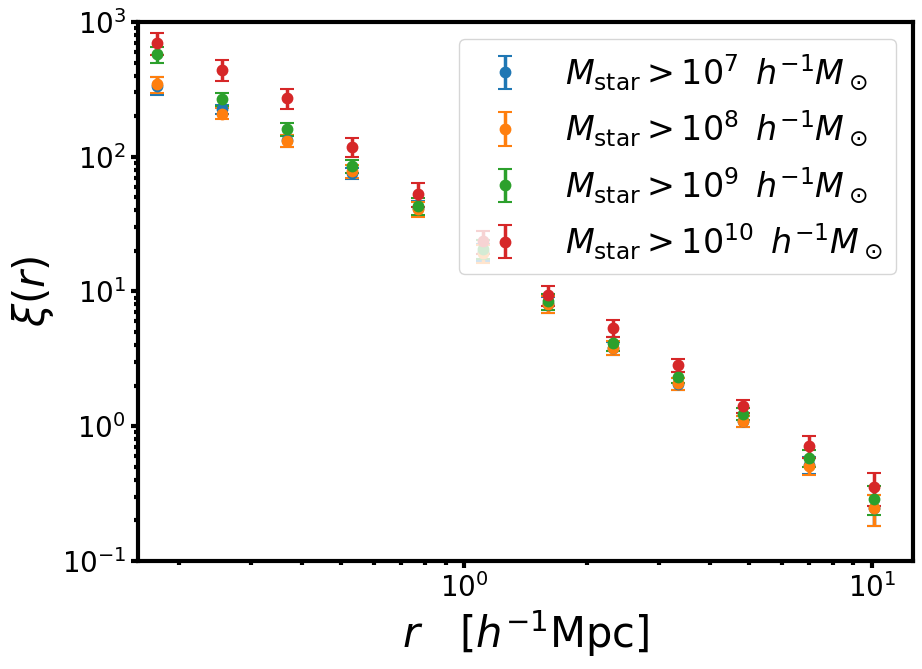

In [11]:
fig, ax = plt.subplots(figsize=(10,7))

# Common errorbar style
err_kwargs = dict(
    fmt='o',
    markersize=7,
    elinewidth=2.5,
    capsize=5,
    capthick=2.5,
    markeredgewidth=1.5,
    alpha=1.0
)

for key in ['10^7', '10^8', '10^9', '10^10']:
    xi  = xi_threshold[key]
    err = errors[key]

    # Protect log-scale plotting (no zero or negative values)
    yerr_lower = np.minimum(err, xi - 1e-6)
    yerr = np.vstack([yerr_lower, err])

    # Main line
    # ax.plot(
    #     rbin_centers,
    #     xi,
    #     color=colors[key],
    #     label=labels[key],
    #     marker='o',
    #     markersize=8,
    #     linewidth=2
    # )

    # Error bars
    ax.errorbar(
        rbin_centers,
        xi,
        yerr=yerr,
        color=colors[key],
        label=labels[key],
        **err_kwargs
    )

# ======================================================
# Formatting
# ======================================================
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlim(10**(-0.8), 10**(1.1)) # Based on Hadzhiyska

ax.set_ylim(10**(-1), 10**(3)) # Based on Hadzhiyska

ax.set_xlabel(r'$r \quad [h^{-1} \rm Mpc]$')
ax.set_ylabel(r'$\xi(r)$')

ax.legend(loc='upper right')

# plt.tight_layout()
# plt.show()
